# Notebook 03 — Feature Engineering and Target Creation
**Project:** Explainable Machine Learning for Chronic Kidney Disease Prediction  

### What we will do
1. Load the cleaned, integrated SMART-C dataset from Notebook 02.
2. Review visits and choose the **Week 52** measurement.
3. Create one row per patient and a simple **binary target**.
4. Encode baseline categorical features and save a dataset for Notebook 04.

**Prediction question:** Based only on baseline information, can we predict whether a patient will have an **eGFR decline of at least 40% at the Week 52 visit**?



## 1. Import libraries and load processed data
We use **Pandas** for data processing and **Pathlib** for file paths. Run the notebook from the project root or the `notebooks` folder. The fallback path supports the original Windows project location.

In [1]:
import pandas as pd
from pathlib import Path

# Find the existing project folder automatically.
windows_project = Path(r"C:\Users\DELL\Desktop\CRONIC KIDNEY DISEASES")
candidates = [Path.cwd(), Path.cwd().parent, windows_project]
project_dir = next(
    (folder for folder in candidates
     if (folder / "datasets" / "processed" / "smart_c_merged.csv").exists()),
    None
)
if project_dir is None:
    raise FileNotFoundError(
        "Cannot find datasets/processed/smart_c_merged.csv. "
        "Open this notebook from your CKD project folder, or update windows_project."
    )

input_path = project_dir / "datasets" / "processed" / "smart_c_merged.csv"
df = pd.read_csv(input_path)

required = {
    "patient_id", "visit_number", "analysis_flag", "egfr_value",
    "baseline_egfr", "treatment_group", "baseline_glp1", "egfr_category"
}
missing_columns = required - set(df.columns)
if missing_columns:
    raise ValueError(f"Missing required columns: {sorted(missing_columns)}")

print("Dataset shape:", df.shape)
print("Unique patients:", df["patient_id"].nunique())
display(df.head(3))

Dataset shape: (41800, 15)
Unique patients: 5000


,patient_id,randomized_flag,itt_flag,treatment_flag,analysis_flag,egfr_value,parameter_code,parameter_name,study_day,visit_number,visit_label,treatment_group,baseline_egfr,baseline_glp1,egfr_category
0,id0001,Y,Y,Y,Y,54,GFRBSCRT,GFR from Creatinine Adjusted for BSA (mL/min/1...,1,0,BASELINE,0,54,N,Screening eGFR 45 to <60 mL/min/1.73m2
1,id0001,Y,Y,Y,Y,51,GFRBSCRT,GFR from Creatinine Adjusted for BSA (mL/min/1...,22,3,WEEK 3,0,54,N,Screening eGFR 45 to <60 mL/min/1.73m2
2,id0001,Y,Y,Y,Y,61,GFRBSCRT,GFR from Creatinine Adjusted for BSA (mL/min/1...,91,13,WEEK 13,0,54,N,Screening eGFR 45 to <60 mL/min/1.73m2


## 2. Understand scheduled visits
The dataset contains **repeated visits** for each patient. Repeated visits are expected, not duplicate patients. We first check how many unique patients were observed at each scheduled visit.

In [2]:
visit_summary = (
    df.groupby(["visit_number", "visit_label"])
      .agg(records=("patient_id", "size"),
           patients=("patient_id", "nunique"))
      .reset_index()
      .sort_values("visit_number")
)
display(visit_summary)

print("Missing analysis flags:", df["analysis_flag"].isna().sum())

,visit_number,visit_label,records,patients
0,0,BASELINE,5000,5000
1,3,WEEK 3,5085,4980
2,13,WEEK 13,4986,4893
3,26,WEEK 26,4905,4810
4,52,WEEK 52,4727,4634
5,78,WEEK 78,4497,4414
6,104,WEEK 104,4358,4272
7,130,WEEK 130,4219,4131
8,156,WEEK 156,4023,3943


Missing analysis flags: 800


## 3. Select baseline records and the Week 52 visit
We only use rows with `analysis_flag == "Y"` for the Week 52 outcome, and check that each selected patient has **one** Week 52 record.

For consistency with our earlier analysis, patients with baseline eGFR **below 30** are excluded. This makes the model population explicit; it is a project design choice, not a general rule for CKD prediction.

Patients without a selected Week 52 measurement are **excluded**, not labeled as healthy.

In [3]:
# One baseline record per patient
baseline = df.loc[df["visit_number"] == 0, [
    "patient_id", "baseline_egfr", "treatment_group",
    "baseline_glp1", "egfr_category"
]].copy()

assert baseline["patient_id"].is_unique, "Baseline has repeated patient IDs."

# Keep the eligible baseline population
baseline = baseline.loc[baseline["baseline_egfr"] >= 30].copy()

# Outcome measurement at Week 52 only
week52 = df.loc[
    (df["visit_number"] == 52) & (df["analysis_flag"] == "Y"),
    ["patient_id", "egfr_value"]
].rename(columns={"egfr_value": "week52_egfr"})

assert week52["patient_id"].is_unique, "Week 52 selected records must be unique by patient."

# Inner join: only patients with an observed Week 52 outcome
patient_data = baseline.merge(week52, on="patient_id", how="inner", validate="one_to_one")

print("Eligible baseline patients:", len(baseline))
print("Eligible patients with selected Week 52 record:", len(patient_data))
print("Excluded because Week 52 is unavailable:", len(baseline) - len(patient_data))
display(patient_data.head())

Eligible baseline patients: 4716
Eligible patients with selected Week 52 record: 4362
Excluded because Week 52 is unavailable: 354


,patient_id,baseline_egfr,treatment_group,baseline_glp1,egfr_category,week52_egfr
0,id0001,54,0,N,Screening eGFR 45 to <60 mL/min/1.73m2,53
1,id0003,50,1,N,Screening eGFR 45 to <60 mL/min/1.73m2,52
2,id0004,47,0,N,Screening eGFR 45 to <60 mL/min/1.73m2,50
3,id0005,75,0,N,Screening eGFR 60 to <90 mL/min/1.73m2,53
4,id0006,30,0,N,Screening eGFR 30 to <45 mL/min/1.73m2,70


## 4. Create the target variable
Percentage decline is calculated as:

\[
\text{eGFR decline (\%)} = \frac{\text{Baseline eGFR} - \text{Week 52 eGFR}}{\text{Baseline eGFR}} \times 100
\]

- **1:** Decline of **40% or more** at Week 52.
- **0:** Decline of **less than 40%** at Week 52 (including stable or improved eGFR).

We keep `week52_egfr` and `egfr_decline_pct` for *checking the target*, but **never use them as model input features**: they contain future information.

In [4]:
patient_data["egfr_decline_pct"] = (
    (patient_data["baseline_egfr"] - patient_data["week52_egfr"])
    / patient_data["baseline_egfr"]
) * 100

# Binary classification target
patient_data["ckd_progression"] = (
    patient_data["egfr_decline_pct"] >= 40
).astype(int)

print("Target distribution (0 = no ≥40% decline; 1 = ≥40% decline):")
print(patient_data["ckd_progression"].value_counts().sort_index())
print("\nTarget percentage:")
print((patient_data["ckd_progression"].value_counts(normalize=True).sort_index() * 100).round(2))
display(patient_data[["patient_id", "baseline_egfr", "week52_egfr", "egfr_decline_pct", "ckd_progression"]].head(10))

Target distribution (0 = no ≥40% decline; 1 = ≥40% decline):
ckd_progression
0    3892
1     470
Name: count, dtype: int64

Target percentage:
ckd_progression
0    89.23
1    10.77
Name: proportion, dtype: float64


,patient_id,baseline_egfr,week52_egfr,egfr_decline_pct,ckd_progression
0,id0001,54,53,1.851852,0
1,id0003,50,52,-4.000000,0
2,id0004,47,50,-6.382979,0
3,id0005,75,53,29.333333,0
4,id0006,30,70,-133.333333,0
5,id0007,56,44,21.428571,0
6,id0008,59,45,23.728814,0
7,id0009,65,52,20.000000,0
8,id0011,45,53,-17.777778,0
9,id0012,98,45,54.081633,1


## 5. Basic checks and visualization
A **count plot** makes the class distribution easy to interpret. If one class is much smaller than the other, simple accuracy alone will be misleading; in Notebook 04 we should also evaluate **precision, recall, F1-score and ROC-AUC**.

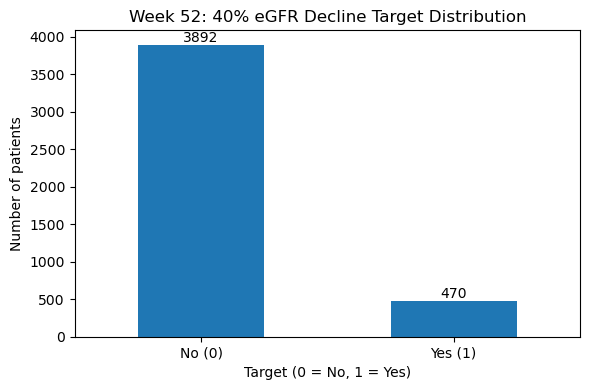

Patient IDs and binary target validated.


In [5]:
import matplotlib.pyplot as plt

counts = patient_data["ckd_progression"].value_counts().reindex([0, 1], fill_value=0)
ax = counts.plot(kind="bar", figsize=(6, 4))
ax.set_title("Week 52: 40% eGFR Decline Target Distribution")
ax.set_xlabel("Target (0 = No, 1 = Yes)")
ax.set_ylabel("Number of patients")
ax.set_xticklabels(["No (0)", "Yes (1)"], rotation=0)
for i, value in enumerate(counts):
    ax.text(i, value, str(value), ha="center", va="bottom")
plt.tight_layout()
plt.show()

assert patient_data["patient_id"].is_unique
assert patient_data["ckd_progression"].isin([0, 1]).all()
print("Patient IDs and binary target validated.")

## 6. Encode baseline features
This applies the **encoding** concept from Data Preprocessing II.

- `baseline_glp1`: convert `N` to 0 and `Y` to 1.
- `egfr_category`: use **one-hot encoding** because screening eGFR categories are categorical.
- `treatment_group` and `baseline_egfr` are already numeric.

**Only baseline variables are predictors.** `patient_id` is an identifier, not a predictor. The screening category is retained as given in the dataset; it is not assumed to be an exact copy of baseline eGFR.

In [6]:
# Start from baseline features + target ONLY; do not copy Week 52 values.
model_data = patient_data[[
    "patient_id", "baseline_egfr", "treatment_group",
    "baseline_glp1", "egfr_category", "ckd_progression"
]].copy()

model_data["baseline_glp1"] = model_data["baseline_glp1"].map({"N": 0, "Y": 1})
if model_data["baseline_glp1"].isna().any():
    raise ValueError("Unexpected or missing baseline_glp1 values; inspect before encoding.")

# Convert each screening category into a 0/1 indicator column.
model_data = pd.get_dummies(
    model_data, columns=["egfr_category"], dtype=int
)

print("Model-ready dataset shape:", model_data.shape)
display(model_data.head())

Model-ready dataset shape: (4362, 8)


,patient_id,baseline_egfr,treatment_group,baseline_glp1,ckd_progression,egfr_category_Screening eGFR 30 to <45 mL/min/1.73m2,egfr_category_Screening eGFR 45 to <60 mL/min/1.73m2,egfr_category_Screening eGFR 60 to <90 mL/min/1.73m2
0,id0001,54,0,0,0,0,1,0
1,id0003,50,1,0,0,0,1,0
2,id0004,47,0,0,0,0,1,0
3,id0005,75,0,0,0,0,0,1
4,id0006,30,0,0,0,1,0,0


## 7. Final quality check and export
Check for missing values and repeated patient IDs, then save the final dataset to `datasets/processed/ckd_model_ready.csv`.

This CSV is the input for **Notebook 04 — Machine Learning**. Perform the **train/test split before fitting any imputer, scaler, feature selector or resampling method** in Notebook 04 to avoid data leakage. No model training is performed in this notebook.

In [7]:
print("Missing values per column:")
print(model_data.isna().sum())
print("\nDuplicate patient IDs:", model_data["patient_id"].duplicated().sum())
print("\nFinal target distribution:")
print(model_data["ckd_progression"].value_counts().sort_index())

assert model_data["patient_id"].is_unique
assert not model_data.isna().any().any(), "Missing values found; investigate before export."
assert "week52_egfr" not in model_data.columns
assert "egfr_decline_pct" not in model_data.columns

output_path = project_dir / "datasets" / "processed" / "ckd_model_ready.csv"
output_path.parent.mkdir(parents=True, exist_ok=True)
model_data.to_csv(output_path, index=False)
print("\nSaved successfully:", output_path)
print("Rows:", len(model_data), "| Columns:", len(model_data.columns))

Missing values per column:
patient_id                                              0
baseline_egfr                                           0
treatment_group                                         0
baseline_glp1                                           0
ckd_progression                                         0
egfr_category_Screening eGFR 30 to <45 mL/min/1.73m2    0
egfr_category_Screening eGFR 45 to <60 mL/min/1.73m2    0
egfr_category_Screening eGFR 60 to <90 mL/min/1.73m2    0
dtype: int64

Duplicate patient IDs: 0

Final target distribution:
ckd_progression
0    3892
1     470
Name: count, dtype: int64

Saved successfully: c:\Users\DELL\Desktop\CRONIC KIDNEY DISEASES\datasets\processed\ckd_model_ready.csv
Rows: 4362 | Columns: 8


## Summary and limitations
**Completed in this notebook:** selected an analysis-flagged Week 52 record, created a one-year ≥40% eGFR decline label, encoded baseline categorical features, verified one row per patient, and exported the dataset.

**Limitations to report:**
- This is a **single Week 52 outcome**, not confirmed sustained progression or a diagnosis.
- Patients without usable Week 52 records were excluded; this may cause selection bias.
- Only a small number of baseline predictors are available in SMART-C; variables described in the original proposal but absent from these files cannot be modeled.
- Treatment assignment may be included as a baseline variable for this benchmark, but model predictions do **not** demonstrate treatment effects.
- We used a ≥40% decline threshold as a transparent **project outcome definition**; it is not a substitute for clinical adjudication.

**Next notebook:** `4_machine_learning.ipynb` — split data, train Logistic Regression / Random Forest / XGBoost, and compare performance. Explainability can follow in Notebook 05.